In [3]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import casadi
    print(f"CasADi version {casadi.__version__} is already installed.")
except ImportError:
    print("CasADi not found. Installing now...")
    %pip install casadi
    import casadi
    print("CasADi successfully installed and imported.")

CasADi version 3.6.7 is already installed.


In [62]:
# Parameters and setup

# Units:
# time: hours
# aggregate concentration: nM
# drug concentration: μM

# kinetic parameters
# α0 = 4 * 1e-13 * (5 * 1e3) ** 2 * 3600
# κ0 = np.sqrt(2 * (3 * 1e-3 * 3600) * (1e-14 * 3600) * (5 * 1e3) ** 3)
α0 = 0.04 # primary 
κ0 = 10 # secondary
n1, n2 = 2, 2
ζ = 50 # drug cost factor

K1, K2 = 1, 1 # 10^-3 nM^-1 = 1 uM^-1

# Control parameters
T = 2
initial_state = [0, 0]
control_steps = 200
control_time0 = T / control_steps # per-step time
u_max = 4

# step propagator for the system

# drug predominantly targeting primary nucleation
def dydt1(_t, _y, _u):
    return np.array([α0 / ((1 + K1 * _u) ** n1) + κ0 * _y[0],
                     _y[0]])

# drug predominantly targeting secondary nucleation
def dydt2(_t, _y, _u):
    return np.array([α0 + κ0 / ((1 + K2 * _u) ** (n2 / 2)) * _y[0],
                     _y[0]])

# casadi integrator
def integrator(dydt, control):
    y = casadi.MX.sym('x', 2)
    u = casadi.MX.sym('p')
    eom = dydt(0, y, u)
    ode = {}
    ode['x'] = y
    ode['p'] = u
    ode['ode'] = casadi.vertcat(*eom)
    
    dt = 0.0001
    tt_sim = np.arange(0, control_time0 + dt / 2, dt)
    simulator = casadi.integrator('S', 'cvodes', ode, 0, tt_sim[1:])
    
    traj = np.array([initial_state])
    for k in range(control_steps):
        res = simulator(x0=traj[-1], p=control[k])
        output = np.array(res["xf"]).T
        traj = np.vstack((traj, output))
    
    tt_tot = np.arange(len(traj.T[0])) * dt
    cost = traj[-1, 1] + ζ * np.sum(control) * control_time0
    return tt_tot, traj, cost

In [63]:
# calculate reference trajectory for no control
REF_SIM = []

for i, dydt in enumerate([dydt1, dydt2]):
    control_sequence = np.zeros(control_steps)
    tt_tot, traj, cost = integrator(dydt, control_sequence)
    REF_SIM.append([tt_tot, traj, cost])

In [64]:
# bang-bang control strategy

# switching times following a bang-bang strategy for primary (t11, t12) and secondary (t21, t22) nucleation
Ts = []
αMax = α0 / ((1 + K1 * u_max) ** n1)
κMax = κ0 / ((1 + K2 * u_max) ** (1 / 2))
t11 = 0
t12 = T - (1/κ0)*np.log(ζ * (u_max) * κ0 / (α0 - αMax))
DeltaT = κ0 / (κ0 - κMax) * (T - (1/κ0)*np.log(ζ * (u_max) * κ0 ** 2 / (α0 * (κ0 - κMax))))
t21 = 0.5 * (T - DeltaT)
t22 = 0.5 * (T + DeltaT)
Ts.append([t11, t12])
Ts.append([t21, t22])

# simulate bang-bang control

RES_CTL_BANGBANG = []
RES_SIM_BANGBANG = []

for i, dydt in enumerate([dydt1, dydt2]):
    print(f"Drug {i+1}: switching times = {Ts[i]}")
    
    # Create bang-bang control sequence
    t_switch1, t_switch2 = Ts[i]
    control_sequence = np.zeros(control_steps)
    
    if i == 0:  # Primary: start with u_max, switch to 0 at t12
        for k in range(control_steps):
            t = k * control_time0
            if t < t_switch2:
                control_sequence[k] = u_max
    else:  # Secondary: start at 0, switch to u_max at t21, back to 0 at t22
        for k in range(control_steps):
            t = k * control_time0
            if t_switch1 <= t < t_switch2:
                control_sequence[k] = u_max
    RES_CTL_BANGBANG.append(control_sequence)
    tt_tot, traj, cost = integrator(dydt, control_sequence)
    RES_SIM_BANGBANG.append([tt_tot, traj, cost])

Drug 1: switching times = [0, np.float64(0.9139399721069461)]
Drug 2: switching times = [np.float64(0.2232589256025782), np.float64(1.776741074397422)]


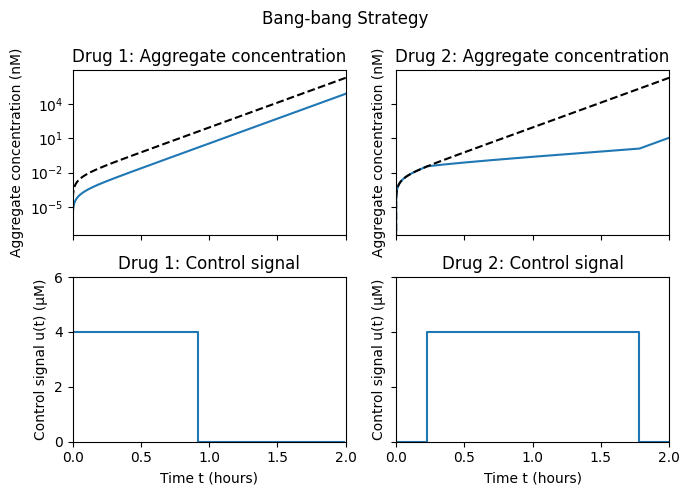

In [65]:
fig, axes = plt.subplots(2, 2, figsize=(7, 5), sharex=True, sharey='row')
for i in range(2):
    axes[0, i].plot(tt_tot, RES_SIM_BANGBANG[i][1][:, 0], label='Bang-bang aggregate concentration')
    axes[0, i].set_title(f'Drug {i+1}: Aggregate concentration')
    axes[0, i].set_ylabel('Aggregate concentration (nM)')
    axes[0, i].set_yscale('log')
    axes[0, i].plot(REF_SIM[i][0], REF_SIM[i][1][:, 0], 'k--', label='Reference (no control)')
    
    axes[1, i].step(np.arange(control_steps) * control_time0, RES_CTL_BANGBANG[i], where='post', label='Bang-bang control signal')
    axes[1, i].set_title(f'Drug {i+1}: Control signal')
    axes[1, i].set_ylabel('Control signal u(t) (μM)')
    axes[1, i].set_xlabel('Time t (hours)')
    axes[1, i].set_ylim(0, 6)
    axes[1, i].set_xlim(0, T)
plt.suptitle('Bang-bang Strategy');
plt.tight_layout()
plt.savefig('aggregation_bang_bang_control.png', dpi=300)

In [66]:
# Casadi optimization
print("Running Casadi optimization...")
RES_CTL_CASADI = []
RES_SIM_CASADI = []
for i, dydt in enumerate([dydt1, dydt2]):
    print(f"  Optimizing drug {i+1} (targeting {'primary' if i == 0 else 'secondary'} nucleation)...")
    
    # Define symbolic variables
    y = casadi.MX.sym('x', 2)
    u = casadi.MX.sym('p')
    eom = dydt(0, y, u)
    
    ode = {}
    ode['x'] = y
    ode['p'] = u
    ode['ode'] = casadi.vertcat(*eom)
    
    # Create integrator for one control step
    C = casadi.integrator('C', 'cvodes', ode, 0, control_time0)
    
    # Direct single shooting: construct optimization problem
    U = casadi.MX.sym("U", control_steps)
    lbx = []
    ubx = []
    
    # Build up state trajectory and cost functional
    X = initial_state
    J = 0
    
    for k in range(control_steps):
        Ck = C(x0=X, p=U[k])
        X = Ck['xf']
        J += ζ * U[k] * control_time0  # drug cost
        lbx.append(0)
        ubx.append(u_max)
    
    J += X[1]  # terminal aggregate load
    
    # Solve NLP
    nlp = {'x': U, 'f': J}
    solver = casadi.nlpsol("solver", "ipopt", nlp, {'ipopt.print_level': 0, 'print_time': 0})
    sol = solver(x0=np.ones(control_steps) * u_max / 2, lbx=lbx, ubx=ubx)
    control_sequence = np.array(sol['x']).flatten()
    RES_CTL_CASADI.append(control_sequence)
    
    tt_tot, traj, cost = integrator(dydt, control_sequence)
    RES_SIM_CASADI.append([tt_tot, traj, cost])

Running Casadi optimization...
  Optimizing drug 1 (targeting primary nucleation)...
  Optimizing drug 2 (targeting secondary nucleation)...


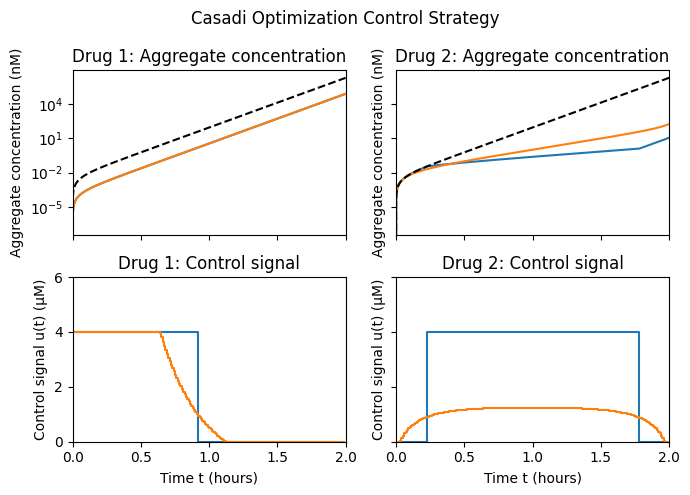

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(7, 5), sharex=True, sharey='row')
for i in range(2):
    tt_tot, traj, cost = RES_SIM_CASADI[i]
    axes[0, i].plot(tt_tot, RES_SIM_BANGBANG[i][1][:, 0], label='Bang-bang aggregate concentration')
    axes[0, i].plot(tt_tot, traj[:, 0], label='Casadi aggregate concentration')
    axes[0, i].set_title(f'Drug {i+1}: Aggregate concentration')
    axes[0, i].set_ylabel('Aggregate concentration (nM)')
    axes[0, i].set_yscale('log')
    axes[0, i].plot(REF_SIM[i][0], REF_SIM[i][1][:, 0], 'k--', label='Reference (no control)')
    
    axes[1, i].step(np.arange(control_steps) * control_time0, RES_CTL_BANGBANG[i], where='post', label='Bang-bang control signal')
    axes[1, i].step(np.arange(control_steps) * control_time0, RES_CTL_CASADI[i], where='post', label='Control signal')
    axes[1, i].set_title(f'Drug {i+1}: Control signal')
    axes[1, i].set_ylabel('Control signal u(t) (μM)')
    axes[1, i].set_xlabel('Time t (hours)')
    axes[1, i].set_ylim(0, 6)
    axes[1, i].set_xlim(0, T)
plt.suptitle('Casadi Optimization Control Strategy');
plt.tight_layout()
plt.savefig('aggregation_optimal_control.png', dpi=300)